In [1]:
import sys
!pip install numpy
!pip install matplotlib
!pip install pandas
!pip install tensorflow
!pip install scikit-learn
!pip install qiskit
!pip install qiskit-machine-learning
!pip install qiskit-aer
!pip install qiskit-aer-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 93.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 92.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.0/109.0 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 99.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 MB 50.0 MB/s eta 0:00:00
  Attempting uninstall: qiskit
    Found existing installation: qiskit 2.1.1
    Uninstalling qiskit-2.1.1:
      Successfully uninstalled qiskit-2.1.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 119.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.2/70.2 MB 32.4 M

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
# from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import clear_output

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42

In [19]:
@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, **kwargs):
        super(AnomalyDetector, self).__init__(**kwargs)
        self.encoder = tf.keras.Sequential([
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(8, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
        ])

        self.decoder = tf.keras.Sequential([
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def get_config(self):
        # Return config dictionary; empty because no constructor args
        base_config = super(AnomalyDetector, self).get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


In [20]:
autoencoder = tf.keras.models.load_model(
    "Models/8f_cae_model.keras",
    custom_objects={"AnomalyDetector": AnomalyDetector}
)

In [21]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [22]:
reduced_normal_training_data = autoencoder.encoder(normal_training_data)
# reduced_normal_training_data = normal_training_data

# filtered_np = normal_training_data.numpy().astype(np.float64)
# target_len = 2**5  # 32 for 5 qubits
# reduced_normal_training_data = np.pad(filtered_np, ((0, 0), (0, target_len - filtered_np.shape[1])), mode='constant')

n_qubits = reduced_normal_training_data.shape[1]

# --- SCALE TO [0, 2π] ---
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)
# scaled_normal_training_data = reduced_normal_training_data.numpy()
# scaled_normal_training_data = reduced_normal_training_data

In [23]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes
import numpy as np

def angle_encoding(x):
    num_qubits = len(x)
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[i], i)
    return circuit

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def efficient_su2_encoding(x):
    num_qubits = int(np.ceil(len(x) / 4))  # EfficientSU2 expects 4 params per qubit per rep
    su2 = EfficientSU2(num_qubits=num_qubits, reps=3)

    # Pad x to match the number of parameters in EfficientSU2
    total_params = su2.num_parameters
    padded_x = np.pad(x, (0, total_params - len(x)), mode='constant')

    circuit = QuantumCircuit(num_qubits)
    circuit.compose(su2.assign_parameters(padded_x), inplace=True)
    return circuit

def amplitude_encoding(x):

    x = np.asarray(x, dtype=np.float64)

    # Replace NaNs and Infs with 0 BEFORE padding
    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    # Pad first
    num_qubits = int(np.ceil(np.log2(len(x))))
    target_len = 2 ** num_qubits
    padded = np.pad(x, (0, target_len - len(x))).astype(np.float64)

    # Normalize
    norm = np.linalg.norm(padded)
    if norm == 0 or not np.isfinite(norm):
        # Default to |0⟩ state if invalid
        normalized = np.zeros_like(padded)
        normalized[0] = 1.0
    else:
        normalized = padded / norm

    # Safety check (this ensures Qiskit won't throw)
    assert np.isclose(np.sum(normalized**2), 1.0, atol=1e-10), f"Vector not normalized: {np.sum(normalized**2)}"

    # Create circuit
    circuit = QuantumCircuit(num_qubits)
    circuit.initialize(normalized, range(num_qubits))
    return circuit


def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

def ansatz(num_qubits):
    # return real_amplitudes(num_qubits, reps=1)
    return pauli_two_design(num_qubits, reps=1)

def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit

In [24]:
from qiskit_aer.primitives import Sampler

# Constants
num_latent = 3
num_trash = 1
total_qubits = num_latent + 2 * num_trash + 1  # encoding + reference + auxiliary

# Step 1: Build the parameterized autoencoder circuit (no encoding here)
ae = auto_encoder_circuit(num_latent, num_trash)

# Step 2: Dummy base circuit (will be composed with encoding later)
# Needed just for QNN init. Actual data circuits will be composed separately.
dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)

# Step 3: Define the Sampler QNN

# sampler = Sampler(backend_options={"device": "GPU", "method": "statevector"},
#                  run_options={"shots": 1024})

# sampler = Sampler(backend_options={"device": "GPU", "method": "statevector"})

sampler = Sampler()

qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=ae.parameters,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)


/tmp/ipykernel_4920/3006446925.py:25: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [25]:
import matplotlib.pyplot as plt

objective_values = []

def cost_function(params, data_subset, qnn, encoding_fn):
    """
    - params: trainable parameters of AE circuit
    - training_data: classical data (e.g., scaled_normal_training_data)
    - qnn: SamplerQNN
    - encoder_func: one of your encoding functions
    """
    total_cost = 0

    num_qubits_encoding = num_latent + num_trash
    total_qubits = num_latent + 2 * num_trash + 1

    for x in data_subset:

        if encoding_fn == amplitude_encoding:
            input_slice = x[:2 ** num_qubits_encoding]
        elif encoding_fn == dense_angle_encoding:
            input_slice = x[:2 * num_qubits_encoding]
        elif encoding_fn == efficient_su2_encoding:
            input_slice = x[:4 * num_qubits_encoding]
        else:
            input_slice = x[:num_qubits_encoding]

        # 2. Encode input
        encoding_circuit = encoding_fn(input_slice)
        encoding_qubits = encoding_circuit.num_qubits

        # 3. Extend encoding to full-size circuit
        full_circuit = QuantumCircuit(total_qubits, 1)
        full_circuit.compose(encoding_circuit, qubits=range(encoding_qubits), inplace=True)

        # 4. Add autoencoder with current parameters
        ae = auto_encoder_circuit(num_latent, num_trash)
        ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, params)})
        full_circuit = full_circuit.compose(ae)

        # 5. Evaluate using the Sampler (NOT qnn.forward!)
        job = qnn.sampler.run([full_circuit])
        result = job.result()
        quasi_dist = result.quasi_dists[0]
        p0 = quasi_dist.get(0, 0)

        total_cost += 1 - p0  # want to maximize p(0)

    avg_cost = total_cost / len(data_subset)
    objective_values.append(avg_cost)

    # Plot current progress
    clear_output(wait=True)
    plt.figure(figsize=(8, 4))
    plt.plot(objective_values, label="Training Loss (1 - p0)")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Training Loss Curve")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return avg_cost


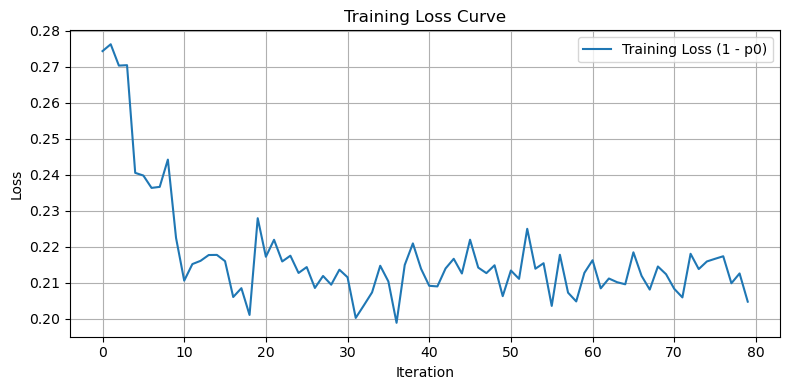

In [26]:
# Use small subset for training speed
subset_size = 1000
subset_indices = np.random.choice(len(scaled_normal_training_data), size=subset_size, replace=False)
training_subset = scaled_normal_training_data[subset_indices]

# Initialize params for AE circuit
num_params = len(auto_encoder_circuit(num_latent, num_trash).parameters)
initial_params = np.random.rand(num_params)

# Optimize
optimizer = COBYLA(maxiter=80)
result = optimizer.minimize(
    fun=lambda p: cost_function(p, training_subset, qnn, dense_angle_encoding),
    x0=initial_params
)
trained_params = result.x


In [27]:
from qiskit.qpy import dump
import os

model_name = "Models/COBLYA_AEs/8f2_qae_dense_pauli"
os.mkdir(model_name)

with open(f"{model_name}/ae.qpy", "wb") as f:
    dump(ae, f)

np.save(f"{model_name}/weight_param_names", [p.name for p in ae.parameters])
np.save(f"{model_name}/trained_parameters", trained_params)

# from qiskit.qpy import load

# model_name = "8f_qae_amplitude_ra_shot"

# trained_params = np.load(f"trained_parameters.npy")

## Testing

In [28]:
transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

reduced_testing_data = autoencoder.encoder(testing_data)
# filtered_np = testing_data.numpy().astype(np.float64)
# target_len = 2**5  # 32 for 5 qubits
# reduced_testing_data = np.pad(filtered_np, ((0, 0), (0, target_len - filtered_np.shape[1])), mode='constant')
# reduced_testing_data = testing_data

# --- SCALE TO [0, 2π] ---|
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)
# scaled_testing_data = reduced_testing_data.numpy()
# scaled_testing_data = reduced_testing_data

In [29]:
from tqdm import tqdm

def compute_anomaly_scores(qnn, input_data, trained_params, encoding_fn, batch_size=64):
    scores = []
    total_qubits = num_latent + 2 * num_trash + 1
    num_encoding_qubits = num_latent + num_trash

    ae = auto_encoder_circuit(num_latent, num_trash)
    ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

    start = time.time()
    for i in tqdm(range(0, len(input_data), batch_size), desc="Running inference"):
        batch = input_data[i : i + batch_size]
        circuits = []

        for x in batch:
            qc = QuantumCircuit(total_qubits, 1)

            # 1. Slice input based on encoding type
            if encoding_fn == amplitude_encoding:
                input_slice = x[:2 ** num_encoding_qubits]
            elif encoding_fn == dense_angle_encoding:
                input_slice = x[:2 * num_encoding_qubits]
            elif encoding_fn == efficient_su2_encoding:
                input_slice = x[:4 * num_encoding_qubits]
            else:
                input_slice = x[:num_encoding_qubits]

            # 2. Encode input
            encoded = encoding_fn(input_slice)
            qc.compose(encoded, qubits=range(encoded.num_qubits), inplace=True)

            # 3. Add trained AE circuit
            qc.compose(ae, inplace=True)

            circuits.append(qc)

        # 4. Run sampler
        job = qnn.sampler.run(circuits)
        result = job.result()

        # 5. Extract p(1) as anomaly score
        for quasi in result.quasi_dists:
            p1 = quasi.get(1, 0)
            scores.append(p1)

    elapsed = time.time() - start
    print(f"\nAll batches processed in {elapsed:.4f} seconds.")

    return np.array(scores), elapsed



In [30]:
train_scores, train_time = compute_anomaly_scores(
    qnn,
    training_subset,
    trained_params,
    encoding_fn=efficient_su2_encoding,
    batch_size=64
)

threshold = 0.5 * (np.min(train_scores) + np.max(train_scores))

Running inference: 100%|████████████████████████| 16/16 [00:15<00:00,  1.05it/s]


All batches processed in 15.2888 seconds.


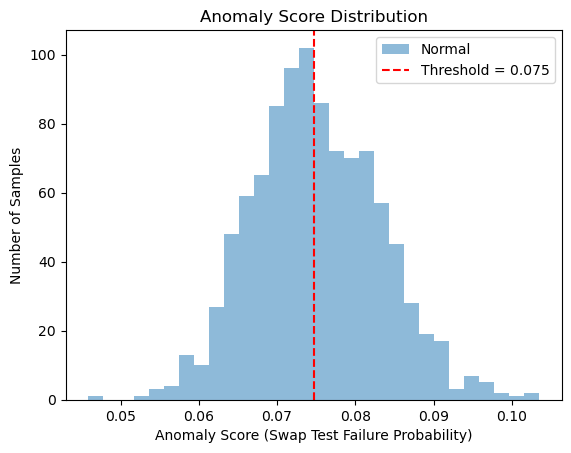

In [31]:
y_pred = (train_scores < threshold).astype(int)

# --- Histogram of scores ---
plt.hist(train_scores, bins=30, alpha=0.5, label='Normal')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()

In [32]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers

def evaluate_model(y_true, y_pred, scores, time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.

    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.

    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Data Loading + Inference Time (s)": f"{time:.4f}s",
        "Clf Report": clf_report.strip()
    }

    return result

In [33]:
scores, elapsed_time = compute_anomaly_scores(
    qnn,
    scaled_testing_data,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64
)

Running inference: 100%|████████████████████| 2953/2953 [08:00<00:00,  6.14it/s]


All batches processed in 480.6112 seconds.


Model: Models/COBLYA_AEs/8f2_qae_dense_pauli
Precision: 0.916
Accuracy: 0.907
Recall: 0.988
F1-Score: 0.951
Matrix: TP=169467, FP=15592, FN=1992, TN=1916
AUROC: 0.583
Data Loading + Inference Time (s): 480.6112s
Clf Report: precision    recall  f1-score   support

           0       0.49      0.11      0.18     17508
           1       0.92      0.99      0.95    171459

    accuracy                           0.91    188967
   macro avg       0.70      0.55      0.56    188967
weighted avg       0.88      0.91      0.88    188967


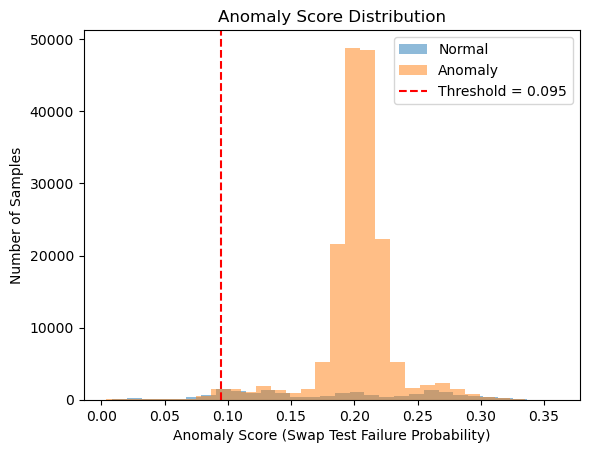

In [37]:
threshold += 0.52

y_pred = (scores > threshold).astype(int)
y_true = np.array(testing_labels).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores,
    time=elapsed_time,
    threshold=threshold,  # same threshold used in predict
    model_name=model_name
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()